# One Year of Simulated Data

This notebook draws the population results of Sec. III and Appendices F and G of the paper from the results of the year analysis, one year of 8 s segments in the two LIGO detectors with the O4 noise curve and binary black-hole mergers from the GWTC-5 mass model with a Madau-Dickinson rate history (Sec. III A). The result files are downloaded into `../data/year` (see the README).

| File | Content |
|---|---|
| `posteriors.npz` | Posterior samples of the seven population parameters for every search |
| `time_curves.npz` | The Bayes factor $\ln\mathcal{B}$ against the observing time |
| `segment_lnB.npz` | The Bayes factor $\ln\mathcal{B}_i$ of every segment |
| `information.npz` | The derivatives $\vec s_i$ of the unresolved mergers and their information $D_{{\rm KL},i}$ |

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import figures_year as figures

posteriors = np.load('../data/year/posteriors.npz')
time_curves = np.load('../data/year/time_curves.npz')
segments = np.load('../data/year/segment_lnB.npz')
information = np.load('../data/year/information.npz')

print('parameters:', ', '.join(str(p) for p in posteriors['parameters']))
print('injected values:', np.round(posteriors['injected'], 2))

parameters: R0, alpha_1, alpha_2, mu_2, gamma, kappa, z_p
injected values: [19.12  1.48  5.42 32.33  2.7   5.6   1.9 ]


## The Population Posteriors of the Two Searches (Fig. 6)

The catalog alone is shown in grey, the uninformed search that uses only the segments below the detection threshold in orange and the catalog-informed search in blue, for $\rho_{\rm th} = 8$ and $n_{\max} = 120$.

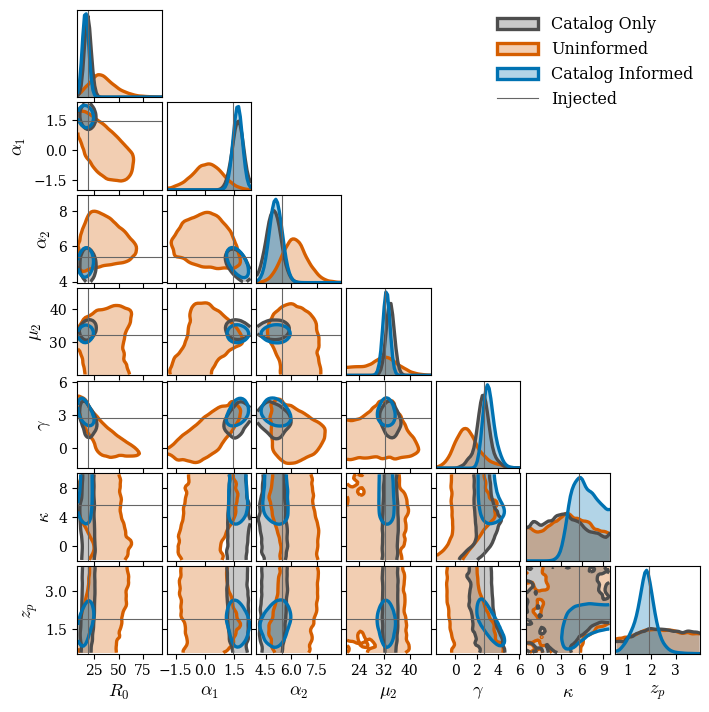

In [2]:
figures.fig_corner_searches(posteriors)

The posterior medians and 90 percent intervals of the catalog-informed search are

In [3]:
samples = posteriors['informed_th8_n120']
for i, name in enumerate(posteriors['parameters']):
    low, median, high = np.percentile(samples[:, i], [5, 50, 95])
    print('%-8s %7.2f  [%6.2f, %6.2f]   injected %6.2f' % (name, median, low, high, posteriors['injected'][i]))

R0         16.13  [ 12.17,  20.50]   injected  19.12
alpha_1     1.70  [  1.33,   2.06]   injected   1.48
alpha_2     5.08  [  4.49,   5.68]   injected   5.42
mu_2       32.66  [ 31.08,  34.15]   injected  32.33
gamma       3.10  [  2.41,   4.16]   injected   2.70
kappa       6.44  [  3.78,   9.57]   injected   5.60
z_p         1.77  [  1.04,   2.41]   injected   1.90


The parameter $z_p$ of the Madau-Dickinson form is not the redshift where the rate peaks. Setting the derivative of $R(z) = R_0 (1+z)^\gamma / [1 + ((1+z)/(1+z_p))^\kappa]$ to zero gives $z_{\rm peak} = (1 + z_p)\,[\gamma/(\kappa - \gamma)]^{1/\kappa} - 1$ for $\kappa > \gamma > 0$, and we transform every posterior sample.

In [4]:
gamma = samples[:, 4]
kappa = samples[:, 5]
z_p = samples[:, 6]

has_peak = (kappa > gamma) & (gamma > 0)
z_peak = (1 + z_p[has_peak]) * (gamma[has_peak] / (kappa[has_peak] - gamma[has_peak])) ** (1 / kappa[has_peak]) - 1
inside = (z_peak > 0) & (z_peak < 10)

true_gamma, true_kappa, true_zp = posteriors['injected'][4:7]
true_z_peak = (1 + true_zp) * (true_gamma / (true_kappa - true_gamma)) ** (1 / true_kappa) - 1

low, median, high = np.percentile(z_peak[inside], [5, 50, 95])
print('probability of a peak between z = 0 and 10: %.2f' % (inside.sum() / samples.shape[0]))
print('z_peak = %.2f  [%.2f, %.2f]   injected %.2f' % (median, low, high, true_z_peak))

probability of a peak between z = 0 and 10: 0.96
z_peak = 1.80  [1.49, 2.90]   injected 1.86


## The Uninformed Search in Ten Independent Years (Fig. 7)

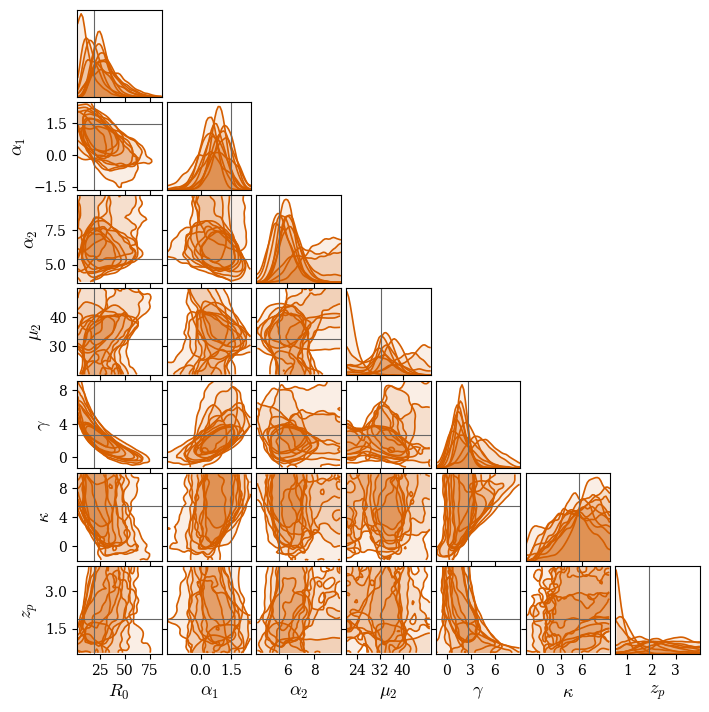

In [5]:
figures.fig_corner_years(posteriors)

## The Mass Distribution and the Rate History (Fig. 8)

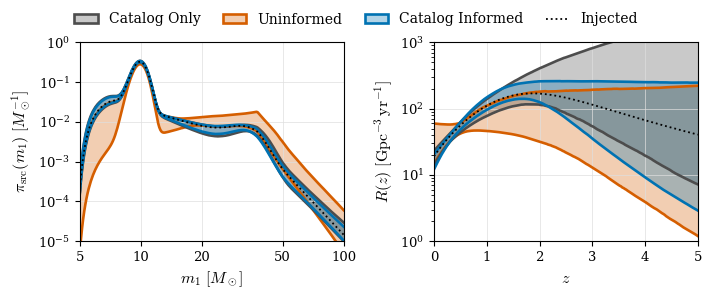

In [6]:
figures.fig_population_searches(posteriors)

## The Mergers That Carry the Information (Fig. 9)

Every unresolved merger is placed at its source-frame primary mass and redshift, and its marker grows with its contribution $s_i^{(j)} s_i^{(k)} / \sqrt{F^{jj} F^{kk}}$ to the Fisher matrix.

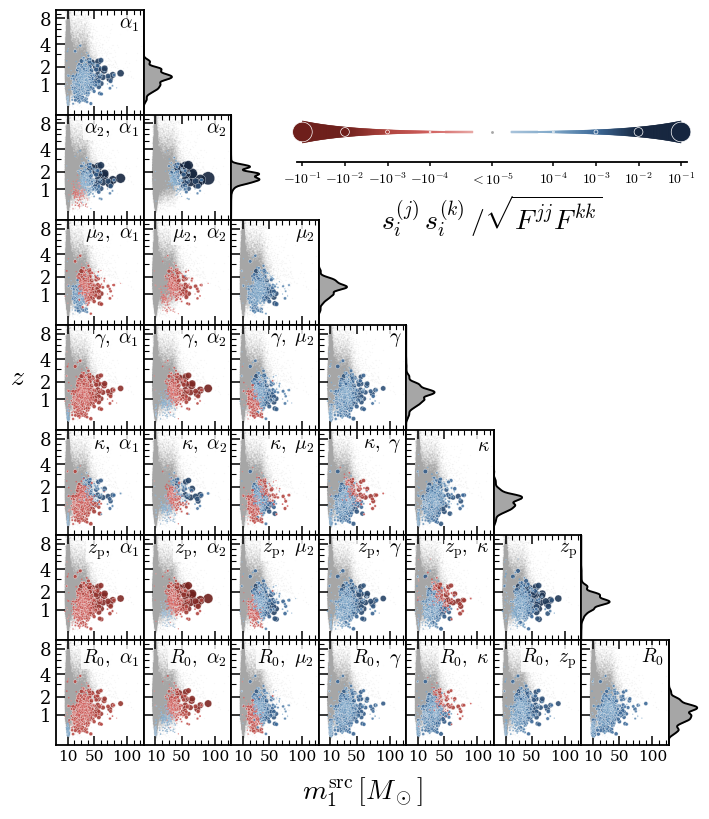

In [7]:
figures.fig_segment_information(information)

## The Bayes Factors of Single Segments (Fig. 10)

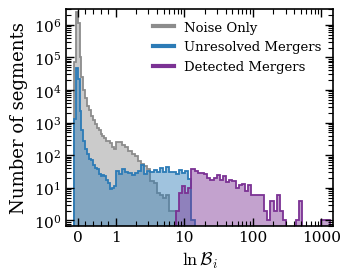

In [8]:
figures.fig_segment_bf_hist(segments)

In [9]:
noise = segments['noise_only_n120']
unresolved = segments['unresolved_mergers_n120']
print('noise-only segments: %d, largest ln B_i = %.2f' % (noise.size, noise.max()))
print('unresolved mergers above the largest noise value: %d of %d' % ((unresolved > noise.max()).sum(), unresolved.size))
print('unresolved mergers with ln B_i > 3: %d' % (unresolved > 3).sum())

noise-only segments: 3868835, largest ln B_i = 7.04
unresolved mergers above the largest noise value: 162 of 75398
unresolved mergers with ln B_i > 3: 434


## The Bayes Factor Against the Observing Time (Fig. 11)

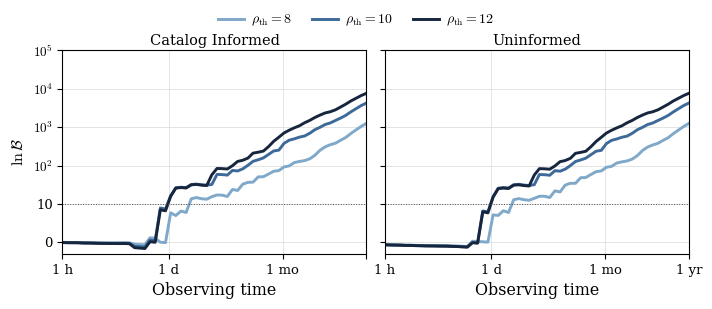

In [10]:
figures.fig_time_thresholds(time_curves)

## Phase-Randomized Data (Figs. 12 and 13)

We show the information $D_{{\rm KL},i}$ of the merger segments (Fig. 12) and the Bayes factors of single segments (Fig. 13) when the phases of every merger are randomized bin by bin.

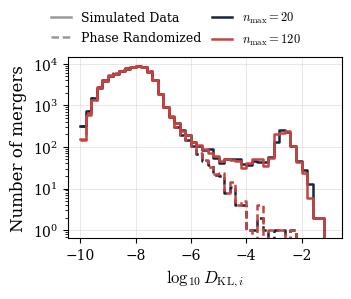

In [11]:
figures.fig_dkl_control(information)

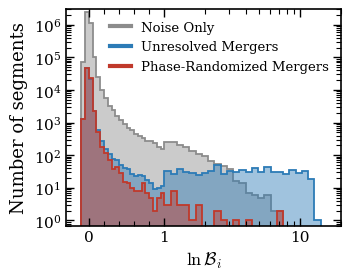

In [12]:
figures.fig_segment_bf_hist(segments, phase_randomized=True)

## Truncation Orders and Thresholds (Appendix F, Figs. 22 to 27)

The posteriors of each search at $n_{\max} = 20$, 40, 80 and 120.

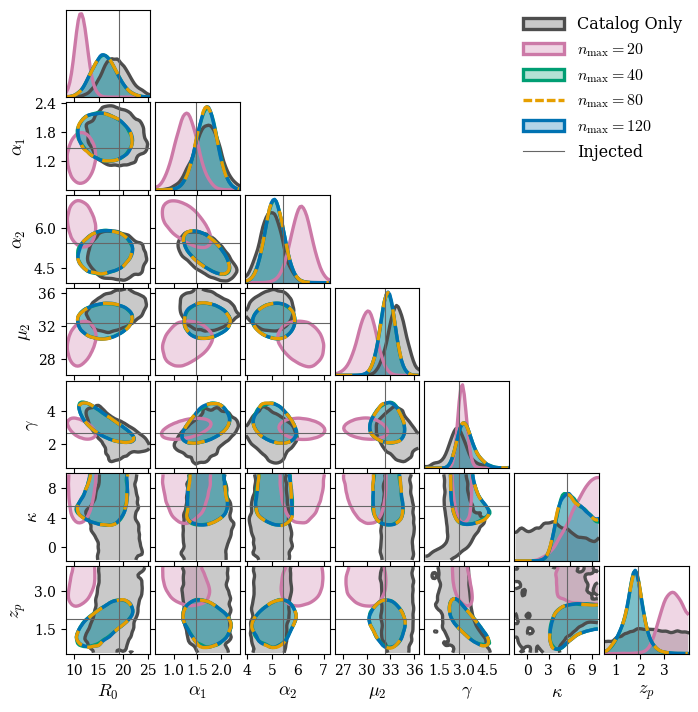

In [13]:
figures.fig_corner_orders(posteriors, 'informed_th8')

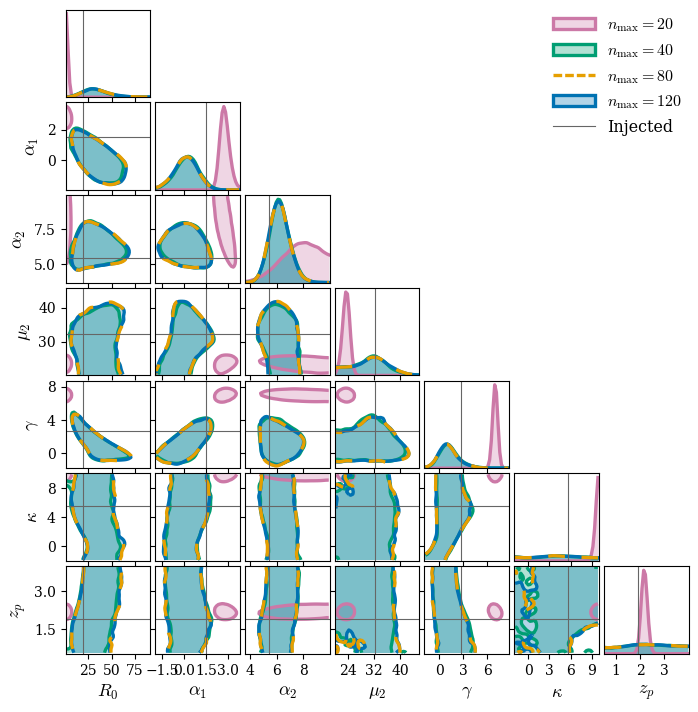

In [14]:
figures.fig_corner_orders(posteriors, 'uninformed_th8')

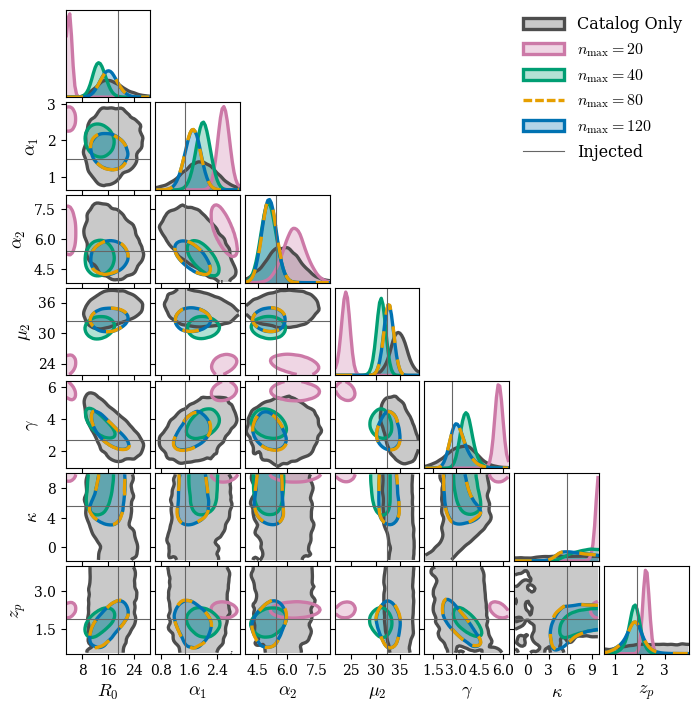

In [15]:
figures.fig_corner_orders(posteriors, 'informed_th12')

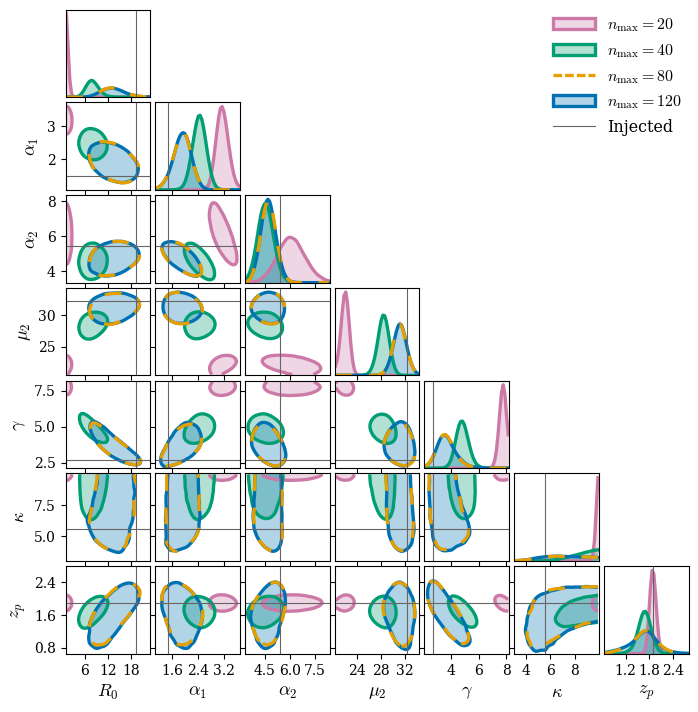

In [16]:
figures.fig_corner_orders(posteriors, 'uninformed_th12')

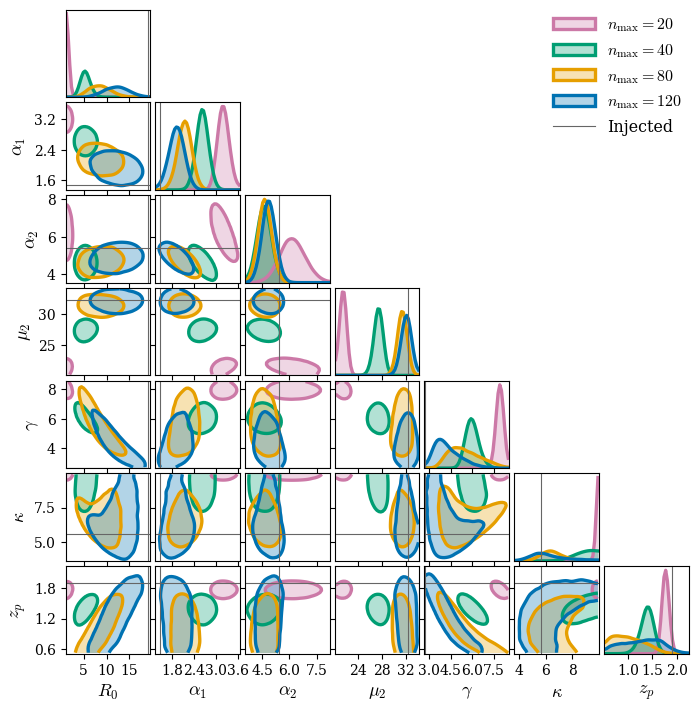

In [17]:
figures.fig_corner_orders(posteriors, 'no_threshold')

Once the segments above the threshold are analyzed separately, the combined posterior must not depend on the threshold, which we check by comparing the catalog-informed searches with $\rho_{\rm th} = 8$ and 12 at $n_{\max} = 120$.

In [18]:
search_8 = posteriors['informed_th8_n120']
search_12 = posteriors['informed_th12_n120']
for i, name in enumerate(posteriors['parameters']):
    shift = (np.median(search_12[:, i]) - np.median(search_8[:, i])) / search_8[:, i].std()
    print('%-8s median shift between the thresholds: %+.2f standard deviations' % (name, shift))

R0       median shift between the thresholds: +0.01 standard deviations
alpha_1  median shift between the thresholds: +0.02 standard deviations
alpha_2  median shift between the thresholds: -0.02 standard deviations
mu_2     median shift between the thresholds: -0.03 standard deviations
gamma    median shift between the thresholds: -0.00 standard deviations
kappa    median shift between the thresholds: +0.02 standard deviations
z_p      median shift between the thresholds: +0.00 standard deviations


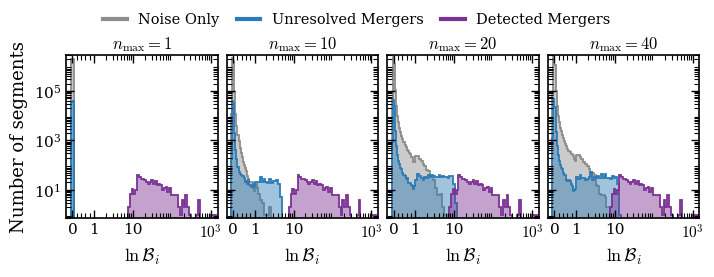

In [19]:
figures.fig_segment_bf_hist(segments, orders=(1, 10, 20, 40))

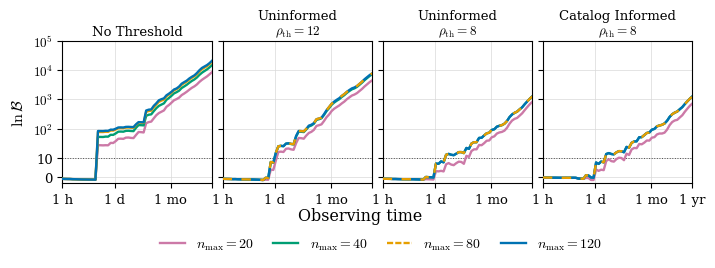

In [20]:
figures.fig_time_versions(time_curves)

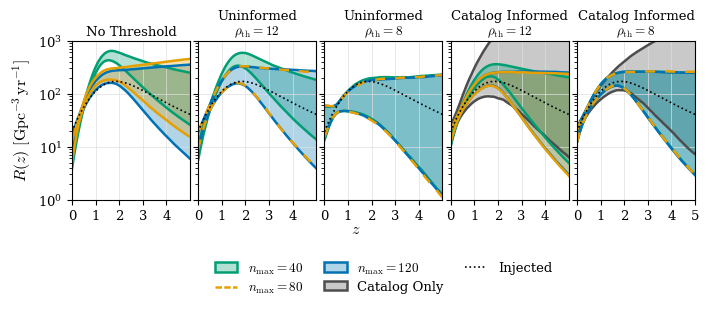

In [21]:
figures.fig_rate_versions(posteriors)

## Years of Noise without Mergers (Appendix G, Fig. 28)

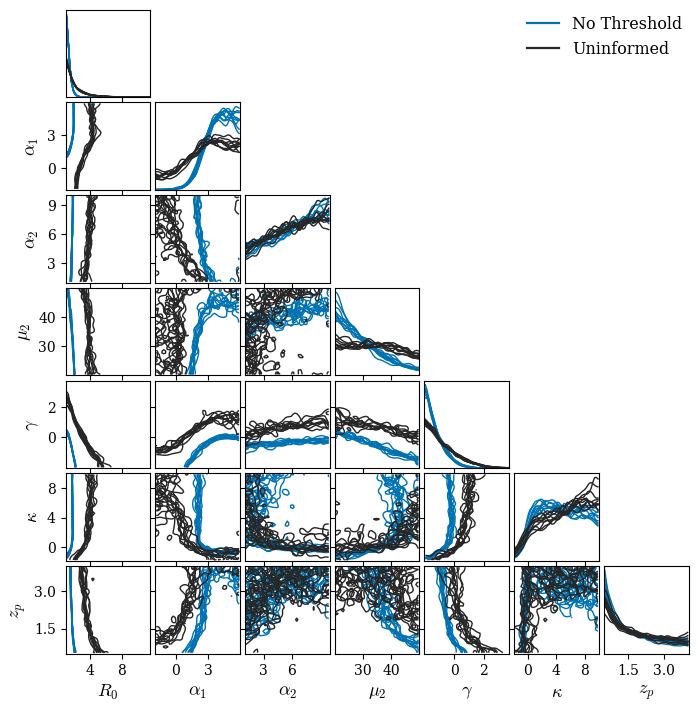

In [22]:
figures.fig_corner_null(posteriors)